#Clustering
จุดประสงค์
---
จัดกลุ่มของข้อมูลเพื่อ
-  วิเคราะห์จำนวนกลุ่มของไวน์
-  สรุปข้อมูลจากกลุ่มของไวน์เพื่อนำไปใช้ประโยชน์ในการจัดจำแนกประเภทกลุ่มลูกค้า

#Design

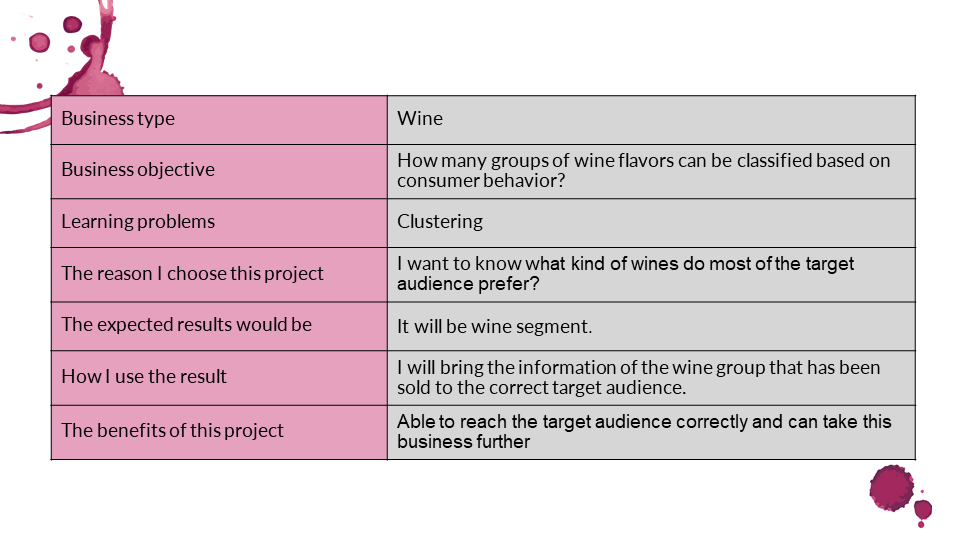

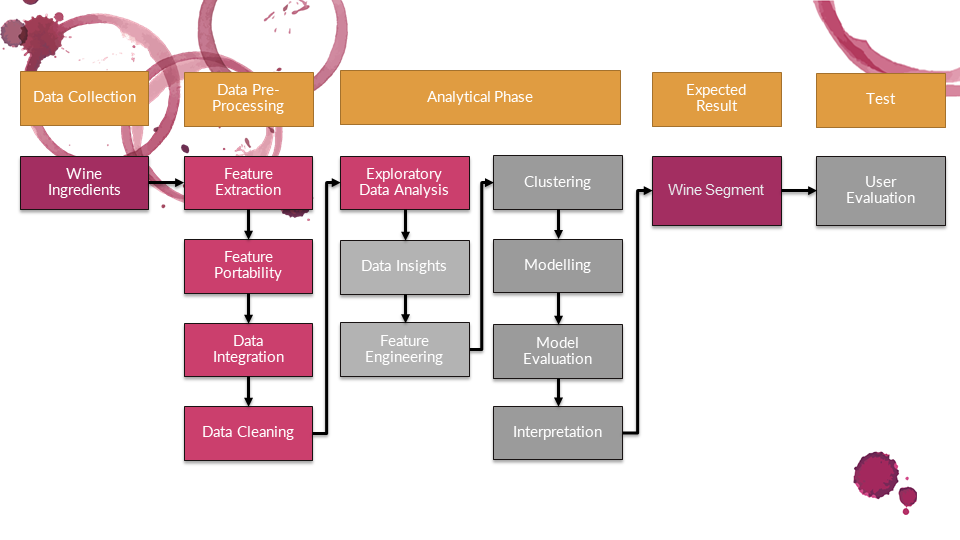

In [ ]:
#Install UMAP
!pip3 install umap-learn
!pip3 install umap-learn[plot]

In [ ]:
# Data Manipulation, Linear Algebra
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid", font_scale=1.5)
import plotly.express as px

# Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import minmax_scale
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import silhouette_score
import umap
from plotly.subplots import make_subplots
import plotly.graph_objects as go

from sklearn.cluster import KMeans

In [ ]:
url = 'https://raw.githubusercontent.com/flukezaza447/cs434_wine_project/main/wine-clustering.csv'
wp = pd.read_csv(url)
wp.reset_index().head()
#wp.head()

#Preprocessing

In [ ]:
wp.dtypes

In [ ]:
# check null
wp.isnull().sum()

In [ ]:
wp.describe()

#EDA and Statistical Analysis

In [ ]:
wp.columns

In [ ]:
# check data stats
plt.rcParams["figure.figsize"] = (20, 15)
wp.hist(bins=20)
plt.show()

In [ ]:
#compare each data
sns.pairplot(wp)
plt.show()

#Feature Engineering
จะทำให้ข้อมูลของ data เป็น normalized เพื่อที่ให้ง่ายต่อการวิเคราะห์ข้อมูลโดยเริ่มจาก scaled ข้อมูลและใช้
- **Box-Cox** จะทำงานได้กับเฉพาะ data ที่มีข้อมูลเป็นค่าบวกเท่านั้น
- **Yeo-Johnson** จะทำงานกับ data ที่มีข้อมูลที่เป็นทั้งค่าบวกและค่าลบ

เพื่อทำให้ข้อมูลเป็น normalized

In [ ]:
# mix-max scale the data between 0 and 1
scaleddf = minmax_scale(wp)

# plot both together to compare
fig, ax=plt.subplots(1,2)
fig.set_size_inches(18,10)
sns.distplot(wp, ax=ax[0], color='y')
ax[0].set_title("Original Data")
sns.distplot(scaleddf, ax=ax[1])
ax[1].set_title("Scaled data")
plt.show()

In [ ]:
# for Box-Cox Transformation
boxcox = PowerTransformer(method='box-cox')
# normalize the exponential data with boxcox
boxcoxdf = boxcox.fit_transform(wp)

#plot both together to compare
fig, ax=plt.subplots(1,2)
fig.set_size_inches(18,10)
sns.distplot(wp, ax=ax[0], color='y')
ax[0].set_title("Original Data")
sns.distplot(boxcoxdf[0], ax=ax[1])
ax[1].set_title("Normalized data")
plt.show()

In [ ]:
# for Yeo-Johnson Transformation
yeo = PowerTransformer(method='yeo-johnson')
# normalize the exponential data with yeo-johnson
yeodf = yeo.fit_transform(wp)

# plot both together to compare
fig, ax=plt.subplots(1,2)
fig.set_size_inches(18,10)
sns.distplot(wp, ax=ax[0], color='y')
ax[0].set_title("Original Data")
sns.distplot(yeodf[0], ax=ax[1])
ax[1].set_title("Normalized data")
plt.show()

#KMeans Model

##Params
ตั้งตัวแปรในการอ้างอิงและใช้ซ้ำ

In [ ]:
SEED = 4
COLUMNS=['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins']

##Modelling
เราจะทำการแยกข้อมูลเป็นกลุ่ม custer k เพื่อใช้ในการจัดจำแนกกลุ่มเป้าหมายที่ต้องการโดยใช้ทั้ง **Box-Cox** และ **Yeo-Johnson**

###Box-Cox Elbow & Silhouette Score



In [ ]:
wssbc = []
silbc = []
# For possible 'k' values 2-10
k = range(2, 11)
for n in k:
    # initialize clustering model
    algorithm = (KMeans(n_clusters = n,random_state=SEED) )
    algorithm.fit(boxcoxdf)
    labels = algorithm.labels_
    wp[f'box_k_{n}']=labels
    # store Weight of sum of squared distance & silhouette score
    wssbc.append(algorithm.inertia_)
    silbc.append(silhouette_score(boxcoxdf, labels, metric = 'euclidean'))

###Yeo-Johnson Elbow & Silhouette Score

In [ ]:
wssyeo = []
silyeo = []
for n in k:
    # initialize clustering model
    algorithm = (KMeans(n_clusters = n,random_state=SEED) )
    algorithm.fit(yeodf)
    labels = algorithm.labels_
    wp[f'yeo_k_{n}']=labels
    # store Weight of sum of squared distance
    wssyeo.append(algorithm.inertia_)
    silyeo.append(silhouette_score(yeodf, labels, metric = 'euclidean'))

##DataFrame
สร้างไว้เพื่อง่ายต่อการค้นหาและนำมาใช้เช็คข้อมูล

In [ ]:
wp

In [ ]:
wp.groupby('box_k_2')[COLUMNS].mean()

#Evaluate Elbow & Siloulette Score

เราจะใช้ตัว **Elbow** และ **Siloulette Score** ใช้และเปรียบเทียบในการหาข้อมูลดังนี้
- จุดตัดของกลุ่ม custer
- คะแนนในแต่ละช่วงของกลุ่ม custer
- กลุ่ม custer ที่เหมาะจะนำมา **Interpretation** และ **Visualizing Clusters**

##Box-Cox

In [ ]:
fig,ax = plt.subplots()
fig.set_size_inches(18,10)
ax.plot(k, wssbc, color="red", marker="o")
ax.set_xlabel("Number of cluster K",fontsize=14)
ax.set_ylabel("Weight of sum of squared distance",color="red",fontsize=14)

ax2=ax.twinx()
ax2.plot(k, silbc,color="blue",marker="o")
ax2.set_ylabel("Siloulette Score",color="blue",fontsize=14)

plt.axvline(3, lw=4, linestyle='--')
plt.show()

##Yeo-Johnson



In [ ]:
fig,ax = plt.subplots()
fig.set_size_inches(18,10)
ax.plot(k, wssyeo, color="red", marker="o")
ax.set_xlabel("Number of cluster K",fontsize=14)
ax.set_ylabel("Weight of sum of squared distance",color="red",fontsize=14)

ax2=ax.twinx()
ax2.plot(k, silyeo,color="blue",marker="o")
ax2.set_ylabel("Siloulette Score",color="blue",fontsize=14)

plt.axvline(3, lw=4, linestyle='--')
plt.show()

#Interpretation
- จะทำการนำข้อมูล custer k ที่เราเลือกจากช่วง evaluate มา plot โดยใช้ตัว **Violin Plot** ในการแยกข้อมูลของกลุ่ม custer เพื่อให้เห็นความแตกต่างของข้อมูลในแต่ละกลุ่ม custer ที่มีผลต่อข้อมูล

In [ ]:
#Color Mapping
def color_change_2d(data,col,k):
  if k==5:
    map = {0:'blue',1:'orange',2:'green',3:'red',4:'purple'}
  elif k==4:
    map = {0:'blue',1:'orange',2:'green',3:'red'}
  elif k==3:
    map = {0:'blue',1:'orange',2:'green'}
  return data[col].map(map)

##Box-Cox

###K=5

In [ ]:
model = KMeans(n_clusters=5,random_state=SEED)
model.fit(boxcoxdf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('box_k_5')[COLUMNS].mean()


In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='box_k_5', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='box_k_5', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'box_k_5',5),size=5,showscale=False)))
fig.update_layout(height=500, title_text="Visualizing 2D Clusters K=5", showlegend=False)
fig.show()

###K=4

In [ ]:
model = KMeans(n_clusters=4,random_state=SEED)
model.fit(boxcoxdf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('box_k_4')[COLUMNS].mean()

In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='box_k_4', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='box_k_4', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'box_k_4',4),size=5,showscale=False)))
fig.update_layout(height=500, title_text="Visualizing 2D Clusters K=4", showlegend=False)
fig.show()

###K=3

In [ ]:
model = KMeans(n_clusters=3,random_state=SEED)
model.fit(boxcoxdf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('box_k_3')[COLUMNS].mean()

In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='box_k_3', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='box_k_3', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'box_k_3',3),size=5,showscale=False)))
fig.update_layout(height=500, title_text="Visualizing 2D Clusters K=3", showlegend=False)
fig.show()

##Yeo-Johnson

###K=5

In [ ]:
model = KMeans(n_clusters=5,random_state=SEED)
model.fit(yeodf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('yeo_k_5')[COLUMNS].mean()

In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='yeo_k_5', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='yeo_k_5', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'yeo_k_5',5),size=5,showscale=False)))
fig.update_layout(height=500,title_text="Visualizing 2D Clusters K=5", showlegend=False)
fig.show()

###K=4

In [ ]:
model = KMeans(n_clusters=4,random_state=SEED)
model.fit(yeodf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('yeo_k_4')[COLUMNS].mean()

In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='yeo_k_4', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='yeo_k_4', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'yeo_k_4',4),size=5,showscale=False)))
fig.update_layout(height=500,title_text="Visualizing 2D Clusters K=4", showlegend=False)
fig.show()

###K=3

In [ ]:
model = KMeans(n_clusters=3,random_state=SEED)
model.fit(yeodf)
model.cluster_centers_.round(4)

In [ ]:
wp.groupby('yeo_k_3')[COLUMNS].mean()

In [ ]:
fig = plt.figure(figsize=(10,5))
sns.countplot(x='yeo_k_3', data=wp);

In [ ]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(28,18))
ax = ax.ravel()
for pos, col in enumerate(COLUMNS):
  # use violinplot to see each cluster's variable is distrubuted
  sns.violinplot(x='yeo_k_3', y=col, data=wp, ax=ax[pos])

In [ ]:
features = wp[COLUMNS]
umap_2d = umap.UMAP(n_components=2, init='random', random_state=SEED)
proj_2d = umap_2d.fit_transform(features)

In [ ]:
fig = go.Figure(data=go.Scatter(x=proj_2d[:,0], y=proj_2d[:,1],
                 mode="markers",
                 marker=dict(color=color_change_2d(wp,'yeo_k_3',3),size=5,showscale=False)))
fig.update_layout(height=500,title_text="Visualizing 2D Clusters K=3", showlegend=False)
fig.show()

##Visualizing Clusters
- ทำการ visualizing clusters แบบ 3D ไปด้วยเพื่อให้เห็นภาพช่วง custer ที่แยกกลุ่มกันอย่างชัดเจน โดยจะใช้วิธี **Umap** ในการ **Visualizing Clusters 3D**

In [ ]:
#Color Mapping
def color_change_3d(data,col,k):
  if k==5:
    map = {0:'blue',1:'orange',2:'green',3:'red',4:'purple'}
  elif k==4:
    map = {0:'blue',1:'orange',2:'green',3:'red'}
  elif k==3:
    map = {0:'blue',1:'orange',2:'green'}
  return data[col].map(map)

###K=5

In [ ]:
features = wp[COLUMNS]
umap_3d = umap.UMAP(n_components=3, init='random', random_state=SEED)
proj_3d = umap_3d.fit_transform(features)

In [ ]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Box-Cox", "Yeo-Johnson"),
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]])

#Box-Cox
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'box_k_5',5),size=5,showscale=False)),
                           row=1, col=1)
#Yeo-Johnson
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'yeo_k_5',5),size=5,showscale=False)),
                           row=1, col=2)
fig.update_layout(height=700,title_text="Visualizing 3D Clusters K=5", showlegend=False)
fig.show()

###K=4

In [ ]:
features = wp[COLUMNS]
umap_3d = umap.UMAP(n_components=3, init='random', random_state=SEED)
proj_3d = umap_3d.fit_transform(features)

In [ ]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Box-Cox", "Yeo-Johnson"),
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]])

#Box-Cox
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'box_k_4',4),size=5,showscale=False)),
                           row=1, col=1)
#Yeo-Johnson
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'yeo_k_4',4),size=5,showscale=False)),
                           row=1, col=2)
fig.update_layout(height=700,title_text="Visualizing 3D Clusters K=4", showlegend=False)
fig.show()

###K=3

In [ ]:
features = wp[COLUMNS]
umap_3d = umap.UMAP(n_components=3, init='random', random_state=SEED)
proj_3d = umap_3d.fit_transform(features)

In [ ]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Box-Cox", "Yeo-Johnson"),
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]])

#Box-Cox
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'box_k_3',3),size=5,showscale=False)),
                           row=1, col=1)
#Yeo-Johnson
fig.add_trace(go.Scatter3d(x=proj_3d[:,0], y=proj_3d[:,1],
                           z=proj_3d[:,2], mode="markers",
                           marker=dict(color=color_change_3d(wp,'yeo_k_3',3),size=5,showscale=False)),
                           row=1, col=2)
fig.update_layout(height=700,title_text="Visualizing 3D Clusters K=3", showlegend=False)
fig.show()

##Conclusion k=3 และ k=4

สรุปแล้วจะได้ **Box-Cox** จาก **Violin Plot** โดยสามารถจัด k ได้หลายกลุ่มแต่เราจะนำ k=3 และ k=4 มาใช้ k=3 จะสามารถจัดกลุ่มได้ชัดเจนที่สุด แต่ k=4 สามารถจัดกลุ่มเป้าหมายได้หลากหลายแต่มีความเสถียรมากกว่า ทำให้ทราบว่า
> สินค้าของเราสามารถจัดกลุ่มรสชาติสินค้าจากส่วนผสมและปริมาณที่ต่างกัน
ซึ่งเราสามารถนำข้อมูลไวน์ที่จัดกลุ่ม นำมาประยุกต์ใช้เพื่อสามารถเลือกสินค้าให้ตรงตามกลุ่มเป้าหมาย โดยกลุ่มเป้าหมายของเราแบ่งออกมาได้ 4 กลุ่ม
- กลุ่มคนชอบรสชาติสไปซ์เข้มข้น (custer 0)
- กลุ่มคนชอบรสชาติเปรี้ยวฝาด (custer 1)
- กลุ่มคนชอบรสชาติหวานครีมมี่ (custer 2)
- กลุ่มคนชอบรสชาติเปรี้ยวหอมอ่อนๆ (custer 3)

ซึ่งข้อมูลการจัดกลุ่มแบบ **k=4** จะสามารถนำมาประยุกต์ใช้ทางธุรกิจให้เกิดประโยชน์ได้มากที่สุด ถึงแม้ว่า k=3 จะถูกแนะนำมากว่าในช่วง evaluate ด้วยคะแนนที่สูง แต่ทางด้านการนำมาใช้ประโยชน์ทางธุรกิจ k=3 อาจจะมีประโยชน์น้อยกว่า k=4

#Pipeline

Preprocessing
>- check data type
- check null

EDA and Statistical Analysis
>- check data stats
- compare each data

Feature Engineering
>ทำข้อมูลให้ Normalized
- Scale
- Box-Cox
- Yeo-Johnson

KMean Model
>- Set Parameter
- Modelling
 - Box-Cox Elbow & Silhouette Score
 - Yeo-Johnson Elbow & Silhouette Score
- DataFrame

Evaluate
>- Elbow & Silhouette Score
 - Box-Cox
 - Yeo-Johnson

Interpretation
>- Box-Cox
 - K=5
 - K=4
 - K=3
>- Yeo-Johnson
 - K=5
 - K=4
 - K=3
>- Visualizing Clusters
 - K=5
 - K=4
 - K=3
- Conclusion

In [ ]:
class Pipeline:
    def __init__(self):
        self.transformer = PowerTransformer(method='box-cox')
        self.columns = ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins']

    def feature_engineering(self,data,method):
        if method == 'train':
          box = self.transformer.fit_transform(data[self.columns])
        elif method == 'predict':
          box = self.transformer.transform(data[self.columns])
        return box

    def build(self,data,method='train'):
        return self.feature_engineering(data,method)

In [ ]:
df_test = pd.read_csv(url)
pipeline = Pipeline()

In [ ]:
wo = pipeline.build(data=df_test,method='train')

In [ ]:
model = KMeans(n_clusters=4,random_state=SEED)
model.fit(wo)

In [ ]:
!pip install gradio -q

In [ ]:
import gradio as gr

#Deployment

In [ ]:
def predict_wine(Alcohol,
                 Malic_Acid,
                 Ash,
                 Ash_Alcanity,
                 Magnesium,
                 Total_Phenols,
                 Flavanoids,
                 Nonflavanoid_Phenols,
                 Proanthocyanins             
                 ):
  
    input = pd.DataFrame({
        'Alcohol': Alcohol,
        'Malic_Acid': Malic_Acid,
        'Ash': Ash,
        'Ash_Alcanity': Ash_Alcanity,
        'Magnesium': Magnesium,
        'Total_Phenols': Total_Phenols,
        'Flavanoids': Flavanoids,
        'Nonflavanoid_Phenols': Nonflavanoid_Phenols,
        'Proanthocyanins': Proanthocyanins,
    }, index=[0])

    wr = pipeline.build(data=input,method='predict')
    groups = ['รสชาติสไปซ์เข้มข้น', 'รสชาติเปรี้ยวฝาด', 'รสชาติหวานครีมมี่', 'รสชาติเปรี้ยวหอมอ่อนๆ']
    return  groups[model.predict(wr)[0]]


Alcohol = gr.inputs.Slider(minimum=1, maximum=20,
                           step=0.5, default=1, label='Alcohol')
Malic_Acid = gr.inputs.Slider(
    minimum=0.1, maximum=10, step=0.1, default=0.1, label='Malic_Acid')
Ash = gr.inputs.Slider(minimum=0.1, maximum=5, step=0.1, default=0.1, label='Ash')
Ash_Alcanity = gr.inputs.Slider(
    minimum=1, maximum=40, step=1, default=1, label='Ash_Alcanity')
Magnesium = gr.inputs.Slider(
    minimum=50, maximum=200, step=1, default=50, label='Magnesium')
Total_Phenols = gr.inputs.Slider(
    minimum=0.1, maximum=5, step=0.1, default=0.1, label='Total_Phenols')
Flavanoids = gr.inputs.Slider(
    minimum=0.1, maximum=10, step=0.1, default=0.1, label='Flavanoids')
Nonflavanoid_Phenols = gr.inputs.Slider(
    minimum=0.1, maximum=1, step=0.1, default=0.1, label='Nonflavanoid_Phenols')
Proanthocyanins = gr.inputs.Slider(
    minimum=0.1, maximum=5, step=0.1, default=0.1, label='Proanthocyanins')

In [ ]:
iface = gr.Interface(
    predict_wine,
    outputs=[gr.outputs.Textbox(type="auto", label='Group')],
    inputs=[Alcohol,
            Malic_Acid,
            Ash,
            Ash_Alcanity,
            Magnesium,
            Total_Phenols,
            Flavanoids,
            Nonflavanoid_Phenols,
            Proanthocyanins
            ])
            
iface.launch(debug=True)

#References

https://github.com/king-glitch/cs-434

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html

https://cmdlinetips.com/2019/10/how-to-make-a-plot-with-two-different-y-axis-in-python-with-matplotlib/

https://colab.research.google.com/drive/1ZpD7sS9ay3QO42x9uNxPRTpf0x_2ll_X?usp=sharing

https://plotly.com/python/line-and-scatter/

https://plotly.com/python/3d-scatter-plots/

https://plotly.com/python/subplots/
